In [102]:
include("GodunovMethod.jl")

MovingGridsDynamicStep (generic function with 1 method)

In [103]:
using DataFrames
using PrettyTables

γ = BigFloat("1.4")
ε = BigFloat("1e-15")

Tests = DataFrame(
    Test = Int8[],
    ρₗ = BigFloat[],
    uₗ = BigFloat[],
    pₗ = BigFloat[],
    ρᵣ = BigFloat[],
    uᵣ = BigFloat[],
    pᵣ = BigFloat[],
    t = BigFloat[]
)

push!(Tests, [1 BigFloat("1.0") BigFloat("0.0") BigFloat("1.0") BigFloat("0.125") BigFloat("0.0") BigFloat("0.1") BigFloat("0.25")])
push!(Tests, [2 BigFloat("1.0") BigFloat("-2.0") BigFloat("0.4") BigFloat("1.0") BigFloat("2.0") BigFloat("0.4") BigFloat("0.15")])
push!(Tests, [3 BigFloat("1.0") BigFloat("0.0") BigFloat("1000.0") BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("0.012")])
push!(Tests, [4 BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("1.0") BigFloat("0.0") BigFloat("100.0") BigFloat("0.035")])
push!(Tests, [5 BigFloat("5.99924") BigFloat("19.5975") BigFloat("460.894") BigFloat("5.99242") BigFloat("-6.19633") BigFloat("46.0950") BigFloat("0.035")])

pretty_table(Tests;
    formatters = [fmt__printf("%.5f", [2, 3, 4, 5, 6, 7, 8])],
    style = TextTableStyle(; table_border = crayon"yellow"),
    fit_table_in_display_horizontally = false,
)

┌──────┬──────────┬──────────┬────────────┬──────────┬──────────┬───────────┬──────────┐
│ Test │       ρₗ │       uₗ │         pₗ │       ρᵣ │       uᵣ │        pᵣ │        t │
│ Int8 │ BigFloat │ BigFloat │   BigFloat │ BigFloat │ BigFloat │  BigFloat │ BigFloat │
├──────┼──────────┼──────────┼────────────┼──────────┼──────────┼───────────┼──────────┤
│    1 │  1.00000 │  0.00000 │    1.00000 │  0.12500 │  0.00000 │   0.10000 │  0.25000 │
│    2 │  1.00000 │ -2.00000 │    0.40000 │  1.00000 │  2.00000 │   0.40000 │  0.15000 │
│    3 │  1.00000 │  0.00000 │ 1000.00000 │  1.00000 │  0.00000 │   0.01000 │  0.01200 │
│    4 │  1.00000 │  0.00000 │    0.01000 │  1.00000 │  0.00000 │ 100.00000 │  0.03500 │
│    5 │  5.99924 │ 19.59750 │  460.89400 │  5.99242 │ -6.19633 │  46.09500 │  0.03500 │
└──────┴──────────┴──────────┴────────────┴──────────┴──────────┴───────────┴──────────┘


In [104]:
using Plots

default(:linewidth, 2)
default(:c, "black")

function exact_plots_moving_grids(TestCase::Int64, xs::Vector{BigFloat})

    default(:xlabel, "Position")
    default(:legend, false)
    default(:xscale, :identity)
    default(:yscale, :identity)
    default(:markersize, 2)
    default(:markerstrokewidth, 0)

    Wₗ = PrimVars(Tuple(Tests[TestCase, 2:4]))
    Wᵣ = PrimVars(Tuple(Tests[TestCase, 5:7]))
    t = Tests[TestCase, 8]

    W = W⁺(Wₗ, Wᵣ, γ, ε)
    ρs = []
    us = []
    ps = []
    Es = []
    for s in xs
        Ws = W(s / t)
        e = Ws.p / (γ - 1) / Ws.ρ
        push!(ρs, Ws.ρ)
        push!(us, Ws.u)
        push!(ps, Ws.p)
        push!(Es, e)
    end
    p = plot(
        plot(xs, ρs, ylabel="Density"),
        plot(xs, us, ylabel="Velocity"),
        plot(xs, ps, ylabel="Pressure"),
        plot(xs, Es, ylabel="Internal energy"),
        layout=(2,2),
        margin=5Plots.mm,
        size=(800,600)
    )

    function BCₗ(t::BigFloat)
        return Wₗ
    end

    function BCᵣ(t::BigFloat)
        return Wᵣ
    end

    function IC(x::BigFloat)
        return x ≥ 0 ? Wᵣ : Wₗ
    end

    Ws, ψs, xs = MovingGridsDynamicStep(xs, γ, t, ε, 
                        BigFloat("0.001"), BigFloat("0.25"), BigFloat("0.05"), BigFloat("0.05"),
                        IC, BCₗ, BCᵣ, true)
    cells = [(xs[i] + xs[i+1]) / 2 for i in 1:(length(xs) - 1)]

    ρs_n = []
    us_n = []
    ps_n = []
    Es_n = []

    for W in Ws
        e = W.p / (γ - 1) / W.ρ
        push!(ρs_n, W.ρ)
        push!(us_n, W.u)
        push!(ps_n, W.p)
        push!(Es_n, e)
    end
    
    scatter!(p[1], cells, ρs_n, c="orange")
    scatter!(p[2], cells, us_n, c="orange")
    scatter!(p[3], cells, ps_n, c="orange")
    scatter!(p[4], cells, Es_n, c="orange")
end

exact_plots_moving_grids (generic function with 1 method)

Moving grids simulation  1955    Time: 0:01:11 (36.32 ms/it)


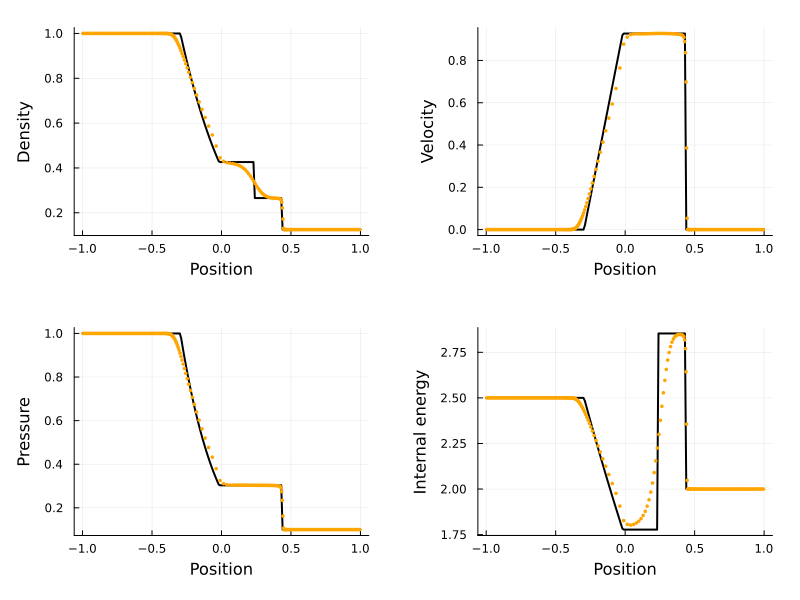

In [106]:
xs = collect(BigFloat("-1"):BigFloat("0.01"):BigFloat("1"))
display(exact_plots_moving_grids(1, xs))
